# Cost per document: receipt extraction at scale with Nemotron 3.5 Super VL

Author: [Zain Hasan](https://x.com/ZainHasan6)

<a target="_blank" href="https://colab.research.google.com/github/togethercomputer/together-cookbook/blob/main/inference/vision/Receipt_Extraction_at_Scale.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Introduction

Before a pipeline that turns receipt photos into structured data goes to production, someone has to answer two questions: how accurate is it, and what does it cost per document? This notebook answers both with measurements.

We use [NVIDIA Nemotron 3.5 Super VL](https://api.together.ai/models/nvidia/NVIDIA-Nemotron-3.5-Super-VL) on Together AI to extract line items and totals from the 100 labeled receipts in the [CORD-v2](https://huggingface.co/datasets/naver-clova-ix/cord-v2) test set. Then we:

1. Score the extractions against human labels.
2. Check each receipt's arithmetic, and re-run only the receipts that don't add up, this time with reasoning turned on (we call this verify-then-escalate).
3. Compare accuracy, latency, and dollars per 1,000 receipts across reasoning settings and against two other serverless vision models.

| | |
| :-- | :-- |
| Model | `nvidia/NVIDIA-Nemotron-3.5-Super-VL` |
| Context length | 262,144 tokens |
| Pricing (per 1M tokens) | \$0.15 input, \$0.50 output |
| Features used | Image input, structured outputs (JSON schema), reasoning toggle |

## Setup

In [1]:
%pip install -qU "together>=3.0.0" "datasets>=5.0.1" "pydantic>=2.4.0" "pillow>=11.3.0" "pandas>=2.0.0" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64
import io
import json
import re
import statistics
import time
from concurrent.futures import ThreadPoolExecutor
from typing import Optional

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from pydantic import BaseModel, Field
from together import Together

# Reads TOGETHER_API_KEY from the environment
client = Together()

MODEL = "nvidia/NVIDIA-Nemotron-3.5-Super-VL"

# (input, output) in $ per 1M tokens, from https://docs.together.ai/docs/serverless/models
PRICES = {
    "nvidia/NVIDIA-Nemotron-3.5-Super-VL": (0.15, 0.50),
    "moonshotai/Kimi-K3": (3.00, 15.00),
    "Qwen/Qwen3.5-9B": (0.17, 0.25),
}

## Load the CORD-v2 receipts

CORD-v2 contains photos of real Indonesian receipts with human-labeled line items and totals. The test split has 100 receipts, few enough to run every configuration in this notebook in a few minutes.

Dataset({
    features: ['image', 'ground_truth'],
    num_rows: 100
})


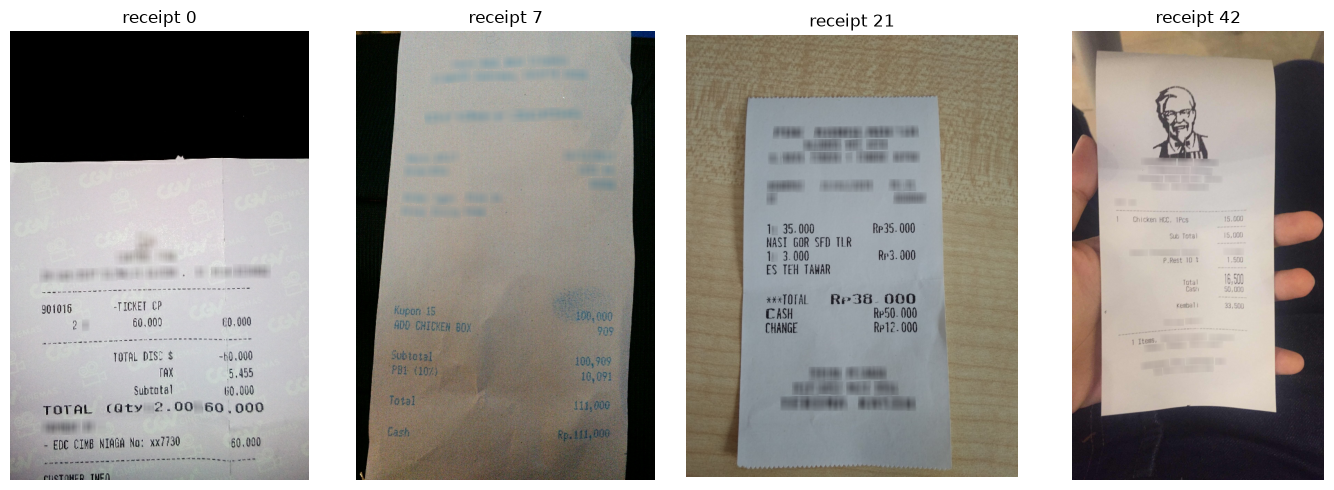

In [3]:
cord = load_dataset("naver-clova-ix/cord-v2", split="test")
print(cord)

fig, axes = plt.subplots(1, 4, figsize=(14, 5))
for ax, i in zip(axes, [0, 7, 21, 42]):
    ax.imshow(cord[i]["image"])
    ax.set_title(f"receipt {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

Each receipt ships with a JSON label. Add-ons such as toppings sit in a nested `sub` field with their own price:

In [4]:
print(json.dumps(json.loads(cord[2]["ground_truth"])["gt_parse"], indent=2))

{
  "menu": {
    "nm": "JASMINE MT ( L )",
    "cnt": "1",
    "price": "24,000",
    "sub": {
      "nm": "COCONUT JELLY ( L )",
      "price": "4,000"
    }
  },
  "sub_total": {
    "subtotal_price": "28,000"
  },
  "total": {
    "total_price": "28,000",
    "cashprice": "100,000",
    "changeprice": "72,000",
    "menuqty_cnt": "1"
  }
}


The labels keep amounts exactly as printed, and receipts print them many ways: `"24,000"`, `"60.000"`, `"17500"`, `"Rp 165000.00"`, and `"9.500,00"` all appear. Rupiah amounts are whole numbers, so a two-digit ending after a separator (`.00`, `,00`) is a cents field. A parser that just keeps the digits turns `"365000.00"` into 36,500,000 and silently marks correct extractions as wrong.

We normalize every label into the same shape the model will produce: a flat list of line-item prices (add-ons included), a subtotal, and a total.

In [5]:
def to_number(value) -> Optional[int]:
    """'24,000' -> 24000, '9.500,00' -> 9500, 'Rp 165000.00' -> 165000, '-60.000' -> -60000."""
    if value is None:
        return None
    if isinstance(value, list):
        value = value[0]
    text = str(value).strip()
    negative = text.replace("Rp", "").strip().startswith("-")
    cents = 0
    decimal = re.search(r"[.,](\d{2})$", text)
    if decimal:
        cents = int(decimal.group(1))
        text = text[: decimal.start()]
    digits = re.sub(r"[^\d]", "", text)
    if not digits:
        return None
    amount = round(int(digits) + cents / 100)
    return -amount if negative else amount


def parse_label(raw: str) -> dict:
    gt = json.loads(raw)["gt_parse"]
    menu = gt.get("menu", [])
    menu = [menu] if isinstance(menu, dict) else menu
    prices = []
    for item in menu:
        if to_number(item.get("price")) is not None:
            prices.append(to_number(item.get("price")))
        subs = item.get("sub", [])
        subs = [subs] if isinstance(subs, dict) else subs
        for sub in subs:
            if isinstance(sub, dict) and to_number(sub.get("price")) is not None:
                prices.append(to_number(sub.get("price")))
    return {
        "item_prices": prices,
        "subtotal": to_number((gt.get("sub_total") or {}).get("subtotal_price")),
        "total": to_number((gt.get("total") or {}).get("total_price")),
    }


for raw in ["24,000", "60.000", "17500", "Rp 165000.00", "9.500,00", "-60.000"]:
    print(f"{raw!r:>16} -> {to_number(raw):,}")

labels = [parse_label(r["ground_truth"]) for r in cord]
print(f"\n{sum(l['total'] is not None for l in labels)} of {len(labels)} receipts have a labeled total")

        '24,000' -> 24,000
        '60.000' -> 60,000
         '17500' -> 17,500
  'Rp 165000.00' -> 165,000
      '9.500,00' -> 9,500
       '-60.000' -> -60,000



95 of 100 receipts have a labeled total


## Define the output schema

Structured outputs let us hand the model a JSON schema and get back JSON that always matches it. We describe a receipt with Pydantic and pass its schema in `response_format`. The field descriptions do real work here: they tell the model where taxes, service charges, and rounding go, and that the total is the amount due rather than the cash handed over.

In [6]:
class LineItem(BaseModel):
    name: str = Field(description="Item name exactly as printed")
    quantity: Optional[float] = Field(default=None, description="Quantity, if printed")
    price: float = Field(description="Line total for this item as printed (after quantity)")


class Receipt(BaseModel):
    items: list[LineItem] = Field(
        description="Every purchased item. List add-ons or modifiers that have their own price as separate items. "
        "Do not list discounts, taxes, or payments here."
    )
    subtotal: Optional[float] = Field(default=None, description="Subtotal before tax and service, if printed")
    tax: Optional[float] = Field(default=None, description="Tax amount, if printed (often labeled Tax, PB1, or PPN)")
    service_charge: Optional[float] = Field(default=None, description="Service charge, if printed (often labeled Service or SC)")
    discount: Optional[float] = Field(default=None, description="Total discount as a positive number, if printed")
    rounding: Optional[float] = Field(
        default=None, description="Rounding adjustment, if printed (often labeled Rounding or Pembulatan); negative if it lowers the total"
    )
    total: float = Field(description="Final amount due after tax, service, discounts, and rounding. Not the cash paid or the change.")


EXTRACTION_PROMPT = (
    "Extract every line item and the totals from this receipt. "
    "Amounts are in Indonesian Rupiah: '24,000', '24.000' and '24000' all mean 24000. "
    "Some receipts print two trailing decimal places ('63,000.00' or '9.500,00'); those are cents, not extra digits. "
    "Return plain numbers without separators. "
    "Capture every charge printed between the subtotal and the total (tax, service, discounts, rounding) in its own field."
)


def image_to_data_url(image) -> str:
    buffer = io.BytesIO()
    image.convert("RGB").save(buffer, format="JPEG", quality=90)
    return "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode()

## Extract one receipt

Nemotron 3.5 Super VL reasons before answering by default. Reading a receipt is mostly a matter of reading printed numbers correctly, so we start with reasoning turned off via `reasoning={"enabled": False}` and measure later whether turning it on helps. We also set `temperature=0` so repeated runs give the same answers.

At `temperature=0` a model occasionally falls into a repetition loop and runs out of tokens mid-JSON. When the output doesn't parse, we retry once at the model's default temperature.

In [7]:
def extract(image, model=MODEL, reasoning=False) -> dict:
    """Extract a Receipt from an image. Returns the parsed receipt plus token usage and latency."""
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image_url", "image_url": {"url": image_to_data_url(image)}},
                {"type": "text", "text": EXTRACTION_PROMPT},
            ],
        }
    ]
    usage = {"input_tokens": 0, "output_tokens": 0}
    start = time.time()
    for attempt, temperature in enumerate([0, None]):
        kwargs = {} if reasoning else {"reasoning": {"enabled": False}}
        if temperature is not None:
            kwargs["temperature"] = temperature
        response = client.chat.completions.create(
            model=model,
            messages=messages,
            response_format={
                "type": "json_schema",
                "json_schema": {"name": "receipt", "schema": Receipt.model_json_schema()},
            },
            max_tokens=16000,
            **kwargs,
        )
        usage["input_tokens"] += response.usage.prompt_tokens
        usage["output_tokens"] += response.usage.completion_tokens
        try:
            receipt = Receipt.model_validate_json(response.choices[0].message.content)
            return {"receipt": receipt, **usage, "seconds": time.time() - start, "attempts": attempt + 1}
        except ValueError:
            if attempt == 1:
                raise


result = extract(cord[2]["image"])
print(result["receipt"].model_dump_json(indent=2))
print(f"\n{result['input_tokens']} input tokens, {result['output_tokens']} output tokens, {result['seconds']:.2f}s")

{
  "items": [
    {
      "name": "JASMINE MT (L)",
      "quantity": null,
      "price": 24000.0
    },
    {
      "name": "COCONUT JELLY (L)",
      "quantity": null,
      "price": 4000.0
    }
  ],
  "subtotal": 28000.0,
  "tax": null,
  "service_charge": null,
  "discount": null,
  "rounding": null,
  "total": 28000.0
}

1248 input tokens, 71 output tokens, 0.63s


## Scoring

We use two metrics. Total accuracy counts a receipt as correct when the extracted `total` exactly matches the labeled total; most downstream systems, such as expense reports and reconciliation, depend on that field. Line-item F1 compares the extracted line-item prices with the labeled ones as multisets. We match on price, not name, because receipts print abbreviated names like `Y.B.BAT` and `J.STB PROMO` that a model may spell out.

In [8]:
def item_f1(predicted: list[int], expected: list[int]) -> float:
    if not predicted and not expected:
        return 1.0
    remaining = list(expected)
    matched = 0
    for price in predicted:
        if price in remaining:
            remaining.remove(price)
            matched += 1
    if matched == 0:
        return 0.0
    precision = matched / len(predicted)
    recall = matched / len(expected)
    return 2 * precision * recall / (precision + recall)


def score(receipt: Receipt, label: dict) -> dict:
    predicted_prices = [round(item.price) for item in receipt.items]
    return {
        "total_correct": None if label["total"] is None else round(receipt.total) == label["total"],
        "item_f1": item_f1(predicted_prices, label["item_prices"]),
    }


print(score(result["receipt"], labels[2]))

{'total_correct': True, 'item_f1': 1.0}


## Run all 100 receipts

Each request is independent, so we send them concurrently. A request that still fails after the retry is recorded as an error instead of crashing the run, and errors count as wrong answers in every metric.

In [9]:
def run_one(index, model=MODEL, reasoning=False):
    try:
        out = extract(cord[index]["image"], model=model, reasoning=reasoning)
        return {"index": index, **out, **score(out["receipt"], labels[index]), "error": None}
    except Exception as exc:
        return {"index": index, "receipt": None, "error": f"{type(exc).__name__}: {exc}"[:200]}


def run_all(indices=None, model=MODEL, reasoning=False, workers=16):
    indices = list(range(len(cord))) if indices is None else list(indices)
    start = time.time()
    with ThreadPoolExecutor(max_workers=workers) as pool:
        results = list(pool.map(lambda i: run_one(i, model, reasoning), indices))
    print(f"{model} (reasoning {'on' if reasoning else 'off'}): {len(results)} receipts in {time.time() - start:.0f}s")
    return results


def summarize(results, label, model=MODEL):
    ok = [r for r in results if r["error"] is None]
    with_total = [r for r in results if labels[r["index"]]["total"] is not None]
    price_in, price_out = PRICES[model]
    cost = sum(r["input_tokens"] * price_in + r["output_tokens"] * price_out for r in ok) / 1e6
    return {
        "config": label,
        "total_accuracy": sum(bool(r.get("total_correct")) for r in with_total) / len(with_total),
        "item_f1": sum(r.get("item_f1", 0.0) for r in results) / len(results),
        "errors": len(results) - len(ok),
        "median_latency_s": statistics.median(r["seconds"] for r in ok),
        "avg_output_tokens": statistics.mean(r["output_tokens"] for r in ok),
        "usd_per_1k_receipts": cost / len(ok) * 1000,
    }


baseline = run_all()
summary = [summarize(baseline, "Nemotron 3.5 Super VL, reasoning off")]
pd.DataFrame(summary).round(4)

nvidia/NVIDIA-Nemotron-3.5-Super-VL (reasoning off): 100 receipts in 5s


,config,total_accuracy,item_f1,errors,median_latency_s,avg_output_tokens,usd_per_1k_receipts
0,"Nemotron 3.5 Super VL, reasoning off",0.9789,0.9111,0,0.599,103.18,0.272


Let's look at the receipts where the total is wrong.

In [10]:
def show_misses(results):
    for r in results:
        if r["error"]:
            print(f"receipt {r['index']:3d}: ERROR {r['error']}")
        elif r["total_correct"] is False:
            print(f"receipt {r['index']:3d}: extracted total {r['receipt'].total:>12,.0f}   labeled {labels[r['index']]['total']:>12,}")


show_misses(baseline)

receipt  67: extracted total       95,000   labeled        9,500
receipt  71: extracted total       22,000   labeled      198,000


## Verify, then escalate

A receipt carries its own checksum: the line items should add up to the subtotal, and the subtotal plus tax, service, and rounding, minus discounts, should equal the total. Let's confirm the first half holds in the human labels:

In [11]:
checkable = [l for l in labels if l["item_prices"] and (l["subtotal"] is not None or l["total"] is not None)]
consistent = [l for l in checkable if sum(l["item_prices"]) == (l["subtotal"] if l["subtotal"] is not None else l["total"])]
print(f"Line items add up to the subtotal (or total) on {len(consistent)} of {len(checkable)} labeled receipts")

Line items add up to the subtotal (or total) on 90 of 95 labeled receipts


The check needs no ground truth, so it runs in production. We use it to route work: every receipt gets the fast reasoning-off pass, and only the receipts whose arithmetic doesn't close get a second pass with reasoning on. We allow a 100 Rupiah tolerance for unprinted rounding.

In [12]:
def arithmetic_problems(receipt: Receipt, tolerance: float = 100) -> list[str]:
    items_sum = sum(item.price for item in receipt.items)
    charges = (receipt.tax or 0) + (receipt.service_charge or 0) - (receipt.discount or 0) + (receipt.rounding or 0)
    problems = []
    if receipt.subtotal is not None and abs(items_sum - receipt.subtotal) > tolerance:
        problems.append(f"items sum to {items_sum:,.0f} but the subtotal is {receipt.subtotal:,.0f}")
    base = receipt.subtotal if receipt.subtotal is not None else items_sum
    if abs(base + charges - receipt.total) > tolerance:
        problems.append(f"subtotal and charges come to {base + charges:,.0f} but the total is {receipt.total:,.0f}")
    return problems


def verify_then_escalate(first_pass, model=MODEL):
    flagged = [r["index"] for r in first_pass if r["error"] is not None or arithmetic_problems(r["receipt"])]
    print(f"{len(flagged)} of {len(first_pass)} receipts fail the check and are escalated to reasoning on")
    second_pass = {r["index"]: r for r in run_all(flagged, model=model, reasoning=True)}
    combined = []
    for r in first_pass:
        second = second_pass.get(r["index"])
        if second is None:
            combined.append(r)
        elif second["error"] is not None:
            combined.append(r)  # keep the first answer if the escalation fails
        else:
            merged = dict(second)
            if r["error"] is None:  # pay for both calls
                merged["input_tokens"] += r["input_tokens"]
                merged["output_tokens"] += r["output_tokens"]
                merged["seconds"] += r["seconds"]
            combined.append(merged)
    return combined, flagged


escalated, flagged = verify_then_escalate(baseline)
summary.append(summarize(escalated, "Nemotron 3.5 Super VL, reasoning off + escalation"))
pd.DataFrame(summary).round(4)

25 of 100 receipts fail the check and are escalated to reasoning on


nvidia/NVIDIA-Nemotron-3.5-Super-VL (reasoning on): 25 receipts in 53s


,config,total_accuracy,item_f1,errors,median_latency_s,avg_output_tokens,usd_per_1k_receipts
0,"Nemotron 3.5 Super VL, reasoning off",0.9789,0.9111,0,0.5990,103.18,0.2720
1,"Nemotron 3.5 Super VL, reasoning off + escalation",0.9895,0.9147,0,0.6513,992.72,0.7768


Here are the escalated receipts, with the first-pass and escalated totals side by side:

In [13]:
first = {r["index"]: r for r in baseline}
final = {r["index"]: r for r in escalated}
rows = []
for i in flagged:
    rows.append(
        {
            "receipt": i,
            "labeled_total": labels[i]["total"],
            "first_pass_total": None if first[i]["error"] else first[i]["receipt"].total,
            "escalated_total": None if final[i]["error"] else final[i]["receipt"].total,
            "first_pass_correct": first[i].get("total_correct"),
            "escalated_correct": final[i].get("total_correct"),
        }
    )
flag_table = pd.DataFrame(rows)
fixed = ((flag_table.first_pass_correct == False) & (flag_table.escalated_correct == True)).sum()  # noqa: E712
broken = ((flag_table.first_pass_correct == True) & (flag_table.escalated_correct == False)).sum()  # noqa: E712
print(f"Escalation fixed {fixed} total(s) and broke {broken}.")
flag_table

Escalation fixed 1 total(s) and broke 0.


,receipt,labeled_total,first_pass_total,escalated_total,first_pass_correct,escalated_correct
0,0,60000.0,60000.0,60000.0,True,True
1,7,111000.0,111000.0,111000.0,True,True
2,9,NaN,14000.0,36000.0,None,None
3,14,281435.0,281435.0,281435.0,True,True
4,20,377859.0,377859.0,377859.0,True,True
5,26,138000.0,138000.0,138000.0,True,True
6,28,426195.0,426195.0,426195.0,True,True
7,31,113886.0,113886.0,113886.0,True,True
8,33,148127.0,148127.0,148127.0,True,True
9,38,664329.0,664329.0,664329.0,True,True


Most flagged receipts were already right. Indonesian receipts often print separate tax and service lines that the model folds into one field or skips, and then the arithmetic doesn't close even though the total is correct. We accept those false alarms, since each one costs a single extra call and the check never needs labels.

The check can't catch everything, either. If the model reads the subtotal as the total *and* skips the tax line, its numbers are internally consistent and it passes. Any remaining misses are listed below.

In [14]:
show_misses(escalated)

receipt  67: extracted total       95,000   labeled        9,500


## Reasoning on for every receipt

For comparison, here is the same run with reasoning turned on (the model's default) for all 100 receipts.

In [15]:
reasoning_on = run_all(reasoning=True)
summary.append(summarize(reasoning_on, "Nemotron 3.5 Super VL, reasoning on"))
pd.DataFrame(summary).round(4)

nvidia/NVIDIA-Nemotron-3.5-Super-VL (reasoning on): 100 receipts in 53s


,config,total_accuracy,item_f1,errors,median_latency_s,avg_output_tokens,usd_per_1k_receipts
0,"Nemotron 3.5 Super VL, reasoning off",0.9789,0.9111,0,0.5990,103.18,0.2720
1,"Nemotron 3.5 Super VL, reasoning off + escalation",0.9895,0.9147,0,0.6513,992.72,0.7768
2,"Nemotron 3.5 Super VL, reasoning on",0.9895,0.9119,0,3.1573,1870.71,1.1618


## Compare with other serverless vision models

Finally, we run the plain single-pass pipeline (reasoning off, no escalation) on two other vision models on Together AI: Kimi K3, a frontier-scale model priced at \$3.00 / \$15.00 per 1M tokens, and Qwen3.5 9B, a small model priced close to Nemotron.

In [16]:
for model, name in [("moonshotai/Kimi-K3", "Kimi K3, reasoning off"), ("Qwen/Qwen3.5-9B", "Qwen3.5 9B, reasoning off")]:
    results = run_all(model=model)
    summary.append(summarize(results, name, model=model))

df = pd.DataFrame(summary)
df.round(4)

moonshotai/Kimi-K3 (reasoning off): 100 receipts in 17s


Qwen/Qwen3.5-9B (reasoning off): 100 receipts in 15s


,config,total_accuracy,item_f1,errors,median_latency_s,avg_output_tokens,usd_per_1k_receipts
0,"Nemotron 3.5 Super VL, reasoning off",0.9789,0.9111,0,0.5990,103.18,0.2720
1,"Nemotron 3.5 Super VL, reasoning off + escalation",0.9895,0.9147,0,0.6513,992.72,0.7768
2,"Nemotron 3.5 Super VL, reasoning on",0.9895,0.9119,0,3.1573,1870.71,1.1618
3,"Kimi K3, reasoning off",1.0000,0.9660,0,2.1033,84.49,11.4243
4,"Qwen3.5 9B, reasoning off",0.9684,0.9280,0,1.6569,78.64,0.3996


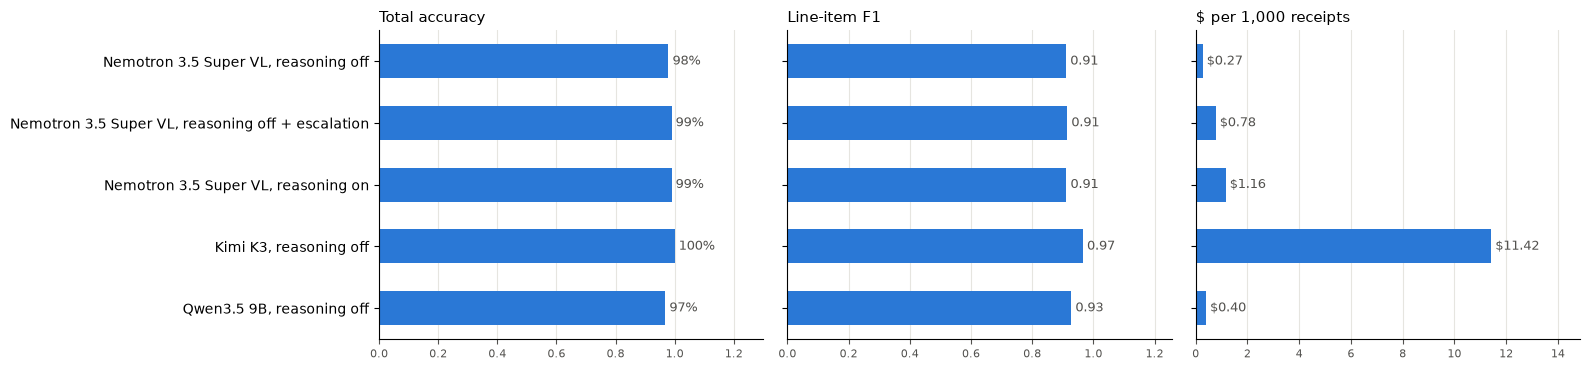

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
order = df.iloc[::-1]
metrics = [
    ("total_accuracy", "Total accuracy", "{:.0%}"),
    ("item_f1", "Line-item F1", "{:.2f}"),
    ("usd_per_1k_receipts", "$ per 1,000 receipts", "${:.2f}"),
]
for ax, (column, title, fmt) in zip(axes, metrics):
    bars = ax.barh(order["config"], order[column], color="#2a78d6", height=0.55)
    for bar, value in zip(bars, order[column]):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, " " + fmt.format(value), va="center", fontsize=9, color="#52514e")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlim(0, order[column].max() * 1.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", colors="#52514e", labelsize=8)
    ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## What it costs at scale

In [18]:
for _, row in df.iterrows():
    print(f"{row['config']:<52} ${row['usd_per_1k_receipts'] * 1000:>10,.2f} per 1M receipts   median {row['median_latency_s']:.1f}s")

Nemotron 3.5 Super VL, reasoning off                 $    271.96 per 1M receipts   median 0.6s
Nemotron 3.5 Super VL, reasoning off + escalation    $    776.84 per 1M receipts   median 0.7s
Nemotron 3.5 Super VL, reasoning on                  $  1,161.84 per 1M receipts   median 3.2s
Kimi K3, reasoning off                               $ 11,424.30 per 1M receipts   median 2.1s
Qwen3.5 9B, reasoning off                            $    399.64 per 1M receipts   median 1.7s


## What we found

These are the results from our run. Yours should be close, since every pass uses `temperature=0`.

A single reasoning-off pass got about 98% of totals right, at roughly \$0.27 per 1,000 receipts and a median latency well under a second. For extraction, reasoning off is a good default.

Turning reasoning on for every receipt matched the escalation pipeline's accuracy, but cost more and took about five times longer per receipt. The arithmetic check sent only a quarter of the receipts down the slower path and fixed the one wrong first-pass total that it flagged. Because the check needs no labels, the same routing works in production.

Kimi K3 read every total correctly, at more than ten times the cost of the Nemotron escalation pipeline. Qwen3.5 9B cost a little more than a single Nemotron pass and missed more totals. Which trade-off is right depends on what one wrong total costs you.

Finally, check the scorer as carefully as the model. A label parser that ignores printed cents, like the one described in the label section, would have marked correct totals such as 365,000 as wrong and made the model look worse than it is.

### Next steps

- To use your own documents, such as invoices or bills of lading, change the Pydantic schema and the arithmetic check.
- Send the first pass through the [Batch API](https://docs.together.ai/docs/batch-inference) for offline backfills.
- Route receipts that still fail the check after escalation to a human reviewer.